Download complete.
Extracting files...
Loading shapefile...


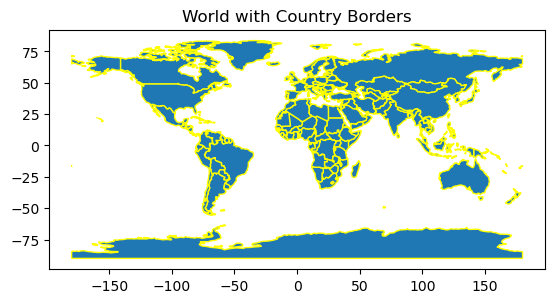

In [7]:
import geopandas as gpd
import matplotlib.pyplot as plt
import os
import requests
import zipfile

# Define file paths
shapefile_url = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
shapefile_zip = "ne_110m_admin_0_countries.zip"
shapefile_dir = "ne_110m_admin_0_countries"
shapefile_path = os.path.join(shapefile_dir, "ne_110m_admin_0_countries.shp")

# Function to download the shapefile
def download_shapefile(url, filename):
    headers = {"User-Agent": "Mozilla/5.0"}  # Mimic a browser request
    response = requests.get(url, headers=headers, stream=True)
    
    if response.status_code == 200:
        with open(filename, "wb") as file:
            for chunk in response.iter_content(chunk_size=1024):
                file.write(chunk)
        print("Download complete.")
    else:
        print(f"Failed to download: HTTP {response.status_code}")
        exit()

# Download and extract if the shapefile doesn't exist
if not os.path.exists(shapefile_path):
    print("Downloading shapefile...")
    download_shapefile(shapefile_url, shapefile_zip)

    print("Extracting files...")
    with zipfile.ZipFile(shapefile_zip, "r") as zip_ref:
        zip_ref.extractall(shapefile_dir)

    os.remove(shapefile_zip)  # Clean up zip file

# Load the shapefile using GeoPandas
print("Loading shapefile...")
world = gpd.read_file(shapefile_path)

# Plot the world map with yellow borders
world.plot(edgecolor="yellow")

# Set title
plt.title("World with Country Borders")
plt.show()
